# Netflix Content Portfolio
### Strategy shifts, country contribution and catalog composition

A catalog-level analysis of Netflix titles, covering the timing of additions, the balance between Movies and TV Shows, genre concentration, country contributions, ratings and series length.

The analysis combines title-level records with exploded genre, country and director credits. Multi-value fields are treated as one-to-many relationships, so a single title can contribute to more than one genre, country or director.

## Scope and source

The source is the **Netflix Movies and TV Shows** dataset published by Shivam Bansal on Kaggle. The file contains 8,807 titles and 12 columns.

The catalog snapshot supports analysis of the `date_added` field and the recorded release year. It does not represent a complete historical archive of every Netflix acquisition, and 2021 is a partial year in this extract.

## Environment and data access

The Desktop location is the preferred source path on the local Windows machine. The project-folder copy is the execution fallback, allowing the notebook to run in a different working environment without changing the analysis.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook")
TYPE_PALETTE = {"Movie": "#315C8C", "TV Show": "#E07A5F"}

In [2]:
desktop_dataset = Path(r"C:\Users\anarrasulzada\Desktop\netflix_titles.csv")
project_dataset = Path("netflix_titles.csv")

file_path = desktop_dataset if desktop_dataset.exists() else project_dataset
if not file_path.exists():
    raise FileNotFoundError(
        "netflix_titles.csv was not found on the Desktop or in the notebook folder."
    )

raw = pd.read_csv(file_path)

print(f"Dataset file: {file_path.name}")
print(f"Dataset size: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

Dataset file: netflix_titles.csv
Dataset size: 8,807 rows × 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## Catalog profile

The source contains two content formats. Movies represent roughly seven tenths of the catalog, while TV Shows account for the remaining three tenths.

In [3]:
profile = pd.DataFrame({
    "metric": [
        "title records",
        "columns",
        "movie titles",
        "tv show titles",
        "distinct release years",
        "distinct genres"
    ],
    "value": [
        len(raw),
        raw.shape[1],
        raw["type"].eq("Movie").sum(),
        raw["type"].eq("TV Show").sum(),
        raw["release_year"].nunique(),
        raw["listed_in"].str.split(",").explode().str.strip().nunique()
    ]
})
display(profile)

type_mix = (
    raw["type"].value_counts()
    .rename_axis("type")
    .reset_index(name="titles")
)
type_mix["share_pct"] = type_mix["titles"] / len(raw) * 100
display(type_mix)

,metric,value
0,title records,8807
1,columns,12
2,movie titles,6131
3,tv show titles,2676
4,distinct release years,74
5,distinct genres,42


,type,titles,share_pct
0,Movie,6131,69.62
1,TV Show,2676,30.38


## Data preparation

Missing director, cast and country values are retained as an explicit `Unknown` category. Addition dates are parsed into calendar year and month fields. Three malformed rating values contain runtime text rather than a content rating; these are classified as `Unknown` alongside the four genuinely missing ratings.

In [4]:
# missing credits are explicit categories
df = raw.copy()

for column in ["director", "cast", "country"]:
    df[column] = df[column].fillna("Unknown").astype("string")

# addition dates define the catalog timing view
df["date_added_parsed"] = pd.to_datetime(
    df["date_added"].astype("string").str.strip(),
    format="%B %d, %Y",
    errors="coerce"
)
df["year_added"] = df["date_added_parsed"].dt.year.astype("Int64")
df["month_added"] = df["date_added_parsed"].dt.month.astype("Int64")
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce").astype("Int64")

df["rating_clean"] = df["rating"].fillna("Unknown").astype("string").str.strip()
# runtime text is not a valid content rating
malformed_rating_mask = df["rating_clean"].str.fullmatch(r"\d+\s*min", case=False, na=False)
df.loc[malformed_rating_mask, "rating_clean"] = "Unknown"

df["season_count"] = pd.to_numeric(
    df["duration"].where(df["type"].eq("TV Show")).str.extract(r"(\d+)")[0],
    errors="coerce"
)

season_labels = ["1 season", "2 seasons", "3 seasons", "4+ seasons"]
df["season_bucket"] = pd.cut(
    df["season_count"],
    bins=[0, 1, 2, 3, np.inf],
    labels=season_labels
)

print(f"Parsed addition dates: {df['date_added_parsed'].notna().sum():,}")
print(f"Missing addition dates: {df['date_added_parsed'].isna().sum():,}")
print(f"Malformed rating entries: {malformed_rating_mask.sum():,}")
print(f"Unusable or missing ratings after cleaning: {df['rating_clean'].eq('Unknown').sum():,}")

Parsed addition dates: 8,797
Missing addition dates: 10
Malformed rating entries: 3
Unusable or missing ratings after cleaning: 7


## Data quality overview

Missingness is concentrated in the director field. The cast and country columns have materially lower missing rates than the approximate 30% noted in the initial project brief. The `date_added` field is missing for ten records, so those titles are excluded only from analyses that require an addition date.

In [5]:
quality = pd.DataFrame({
    "missing_values": raw.isna().sum(),
    "missing_share_pct": raw.isna().mean() * 100
}).sort_values("missing_values", ascending=False)

display(quality)

missing_summary = pd.DataFrame({
    "field": ["director", "cast", "country", "date_added", "rating", "duration"],
    "missing_rows": [raw[c].isna().sum() for c in ["director", "cast", "country", "date_added", "rating", "duration"]],
    "missing_pct": [raw[c].isna().mean() * 100 for c in ["director", "cast", "country", "date_added", "rating", "duration"]]
})
display(missing_summary.round(2))

,missing_values,missing_share_pct
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


,field,missing_rows,missing_pct
0,director,2634,29.91
1,cast,825,9.37
2,country,831,9.44
3,date_added,10,0.11
4,rating,4,0.05
5,duration,3,0.03


## Year of addition: growth and format mix

The `date_added` field spans 2008–2021. The yearly pivot separates title volume from the Movie/TV Show mix, making it possible to distinguish catalog growth from a change in content format.

In [6]:
# 2021 is a partial addition year in this snapshot
analysis_df = df[df["year_added"].between(2008, 2021).fillna(False)].copy()

yearly_counts = pd.crosstab(
    analysis_df["year_added"],
    analysis_df["type"]
).reindex(index=range(2008, 2022), columns=["Movie", "TV Show"], fill_value=0)

yearly_share = yearly_counts.div(
    yearly_counts.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

yearly_summary = yearly_counts.copy()
yearly_summary["Total"] = yearly_counts.sum(axis=1)
yearly_summary["Movie share %"] = yearly_share["Movie"]
yearly_summary["TV Show share %"] = yearly_share["TV Show"]

display(yearly_summary.round(2))

type,Movie,TV Show,Total,Movie share %,TV Show share %
year_added,,,,,
2008,1,1,2,50.00,50.00
2009,2,0,2,100.00,0.00
2010,1,0,1,100.00,0.00
2011,13,0,13,100.00,0.00
2012,3,0,3,100.00,0.00
2013,6,5,11,54.55,45.45
2014,19,5,24,79.17,20.83
2015,56,26,82,68.29,31.71
2016,253,176,429,58.97,41.03


## Release year versus addition year

The addition-year pivot describes when titles entered the catalog. The release-year pivot describes the age profile of the catalog itself. These are different views and should not be interpreted interchangeably.

In [7]:
release_year_pivot = pd.crosstab(df["release_year"], df["type"])
release_year_recent = release_year_pivot.loc[2010:2021].reindex(
    columns=["Movie", "TV Show"], fill_value=0
)
release_year_recent["Total"] = release_year_recent.sum(axis=1)
display(release_year_recent)

release_year_decade = (
    df.assign(release_decade=(df["release_year"] // 10) * 10)
      .pivot_table(index="release_decade", columns="type", values="show_id",
                   aggfunc="nunique", fill_value=0)
      .reindex(columns=["Movie", "TV Show"], fill_value=0)
)
release_year_decade["Total"] = release_year_decade.sum(axis=1)
display(release_year_decade.tail(10))

type,Movie,TV Show,Total
release_year,,,
2010,154,40,194
2011,145,40,185
2012,173,64,237
2013,225,63,288
2014,264,88,352
2015,398,162,560
2016,658,244,902
2017,767,265,1032
2018,767,380,1147


type,Movie,TV Show,Total
release_decade,,,
1920,0,1,1
1940,13,2,15
1950,11,0,11
1960,23,2,25
1970,66,4,70
1980,122,7,129
1990,241,33,274
2000,677,133,810
2010,4184,1743,5927


## Genre structure

The `listed_in` field contains multiple genre labels per title. Exploding this field creates one row per title–genre association, which gives a more faithful genre count than treating the original comma-separated string as a single category.

In [8]:
# one title can carry several genre labels
genre_exploded = (
    df[["show_id", "type", "listed_in"]]
    .assign(genre=lambda frame: frame["listed_in"].str.split(","))
    .explode("genre")
)
genre_exploded["genre"] = genre_exploded["genre"].str.strip()
genre_exploded = genre_exploded.drop_duplicates(["show_id", "genre"])

genre_counts = (
    genre_exploded.groupby("genre")["show_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("title_count")
)

top_15_genres = genre_counts.head(15).reset_index()
genre_label_total = len(genre_exploded)

display(top_15_genres)
print(f"Title–genre associations: {genre_label_total:,}")
print(f"Distinct genre labels: {genre_exploded['genre'].nunique():,}")

,genre,title_count
0,International Movies,2752
1,Dramas,2427
2,Comedies,1674
3,International TV Shows,1351
4,Documentaries,869
5,Action & Adventure,859
6,TV Dramas,763
7,Independent Movies,756
8,Children & Family Movies,641
9,Romantic Movies,616


Title–genre associations: 19,323
Distinct genre labels: 42


## Country contribution

The `country` field is also multi-valued. Each country is counted separately after splitting the field on commas. Consequently, country counts represent title–country credits, not mutually exclusive market shares of the full catalog.

In [9]:
# country credits are multi-valued rather than exclusive
country_exploded = (
    df[["show_id", "type", "country", "release_year", "year_added"]]
    .assign(country_item=lambda frame: frame["country"].str.split(","))
    .explode("country_item")
)
country_exploded["country_item"] = country_exploded["country_item"].str.strip()
country_exploded = country_exploded.drop_duplicates(["show_id", "country_item"])

country_counts = (
    country_exploded[country_exploded["country_item"].ne("Unknown")]
    .groupby("country_item")["show_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("title_count")
)

top_10_countries = country_counts.head(10).index.tolist()

country_type = (
    country_exploded[country_exploded["country_item"].isin(top_10_countries)]
    .pivot_table(
        index="country_item",
        columns="type",
        values="show_id",
        aggfunc="nunique",
        fill_value=0
    )
    .reindex(index=top_10_countries, columns=["Movie", "TV Show"], fill_value=0)
)
country_type["Total"] = country_type.sum(axis=1)

display(country_type)

type,Movie,TV Show,Total
country_item,,,
United States,2752,938,3690
India,962,84,1046
United Kingdom,534,272,806
Canada,319,126,445
France,303,90,393
Japan,119,199,318
Spain,171,61,232
South Korea,61,170,231
Germany,182,44,226


## TV Show season profile

Season counts are extracted from the `duration` field for TV Shows only. The four reporting bands separate one-season series from longer-running formats.

In [10]:
tv_shows = df[df["type"].eq("TV Show")].copy()

season_counts = (
    tv_shows["season_bucket"]
    .value_counts()
    .reindex(season_labels, fill_value=0)
    .rename("titles")
)
season_distribution = season_counts.to_frame()
season_distribution["share_pct"] = season_distribution["titles"] / len(tv_shows) * 100

display(season_distribution.round(2))

,titles,share_pct
season_bucket,,
1 season,1793,67.00
2 seasons,425,15.88
3 seasons,199,7.44
4+ seasons,259,9.68


## Content rating profile

The rating field combines television classifications and film ratings. The comparison is therefore a view of the labels used in the catalog, rather than a single standardized age scale across both formats.

In [11]:
# rating labels combine film and television systems
rating_counts = (
    df.groupby(["rating_clean", "type"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Movie", "TV Show"], fill_value=0)
)

rating_order = rating_counts.sum(axis=1).sort_values(ascending=False).index
rating_counts = rating_counts.loc[rating_order]

rating_share_by_type = rating_counts.div(
    df["type"].value_counts().reindex(["Movie", "TV Show"]),
    axis=1
) * 100

rating_summary = rating_counts.copy()
rating_summary["Total"] = rating_summary.sum(axis=1)
display(rating_summary)
display(rating_share_by_type.round(2))

type,Movie,TV Show,Total
rating_clean,,,
TV-MA,2062,1145,3207
TV-14,1427,733,2160
TV-PG,540,323,863
R,797,2,799
PG-13,490,0,490
TV-Y7,139,195,334
TV-Y,131,176,307
PG,287,0,287
TV-G,126,94,220


type,Movie,TV Show
rating_clean,,
TV-MA,33.63,42.79
TV-14,23.28,27.39
TV-PG,8.81,12.07
R,13.00,0.07
PG-13,7.99,0.00
TV-Y7,2.27,7.29
TV-Y,2.14,6.58
PG,4.68,0.00
TV-G,2.06,3.51


## Addition seasonality

The monthly profile uses all records with a valid `date_added`. Month counts are aggregated across the available years, so they describe the seasonality of this catalog snapshot rather than a single-year release calendar.

In [12]:
month_order = list(range(1, 13))
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

monthly_counts = (
    analysis_df["month_added"]
    .value_counts()
    .reindex(month_order, fill_value=0)
    .rename("titles")
)
monthly_summary = monthly_counts.to_frame()
monthly_summary.index = month_names
monthly_summary["share_pct"] = monthly_summary["titles"] / monthly_summary["titles"].sum() * 100

display(monthly_summary.round(2))

,titles,share_pct
Jan,738,8.39
Feb,563,6.40
Mar,742,8.43
Apr,764,8.68
May,632,7.18
Jun,728,8.28
Jul,827,9.40
Aug,755,8.58
Sep,770,8.75
Oct,760,8.64


## Bonus analysis: release-to-addition lag by country

The lag is calculated as `year_added − release_year`. A larger positive value indicates that a title entered the recorded Netflix catalog further after its original release year. Country-level averages are shown only for countries with at least ten title credits; medians are included because long-tail catalog titles can pull the mean upward.

In [13]:
# negative gaps remain visible as chronology exceptions
country_lag = country_exploded.dropna(
    subset=["year_added", "release_year"]
).copy()

country_lag["release_lag_years"] = (
    country_lag["year_added"].astype(int) -
    country_lag["release_year"].astype(int)
)

country_lag_summary = (
    country_lag[country_lag["country_item"].ne("Unknown")]
    .groupby("country_item")
    .agg(
        title_count=("show_id", "nunique"),
        mean_gap_years=("release_lag_years", "mean"),
        median_gap_years=("release_lag_years", "median")
    )
    .query("title_count >= 10")
    .sort_values("mean_gap_years", ascending=False)
)

display(country_lag_summary.head(10).round(2))
print(
    "Titles with a negative addition-year gap:",
    country_lag.loc[country_lag["release_lag_years"].lt(0), "show_id"].nunique()
)

,title_count,mean_gap_years,median_gap_years
country_item,,,
Hong Kong,105,13.75,8.00
Poland,41,10.88,1.00
Egypt,117,10.78,6.00
Lebanon,31,10.19,3.00
India,1046,6.69,3.00
New Zealand,33,6.03,2.00
Malaysia,26,5.77,2.00
United States,3684,5.69,1.00
Italy,100,5.53,1.00


Titles with a negative addition-year gap: 14


## Bonus analysis: director portfolio

Director names are split into individual credits before counting. The genre matrix describes title–genre associations among the five directors with the largest number of distinct titles in this catalog.

In [14]:
# shared directing credits remain attached to each director
director_exploded = (
    df[["show_id", "director", "listed_in"]]
    .assign(director_item=lambda frame: frame["director"].str.split(","))
    .explode("director_item")
)
director_exploded["director_item"] = director_exploded["director_item"].str.strip()
director_exploded = director_exploded.drop_duplicates(["show_id", "director_item"])
director_exploded = director_exploded[director_exploded["director_item"].ne("Unknown")]

director_counts = (
    director_exploded.groupby("director_item")["show_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("title_count")
)

top_5_directors = director_counts.head(5).index.tolist()
top_director_table = director_counts.head(5).reset_index()
display(top_director_table)

director_genre = (
    director_exploded[director_exploded["director_item"].isin(top_5_directors)]
    .assign(genre=lambda frame: frame["listed_in"].str.split(","))
    .explode("genre")
)
director_genre["genre"] = director_genre["genre"].str.strip()

director_genre_matrix = (
    director_genre.pivot_table(
        index="director_item",
        columns="genre",
        values="show_id",
        aggfunc="nunique",
        fill_value=0
    )
    .reindex(index=top_5_directors)
)

director_genre_matrix = director_genre_matrix.loc[
    :, director_genre_matrix.sum(axis=0).sort_values(ascending=False).index
]
display(director_genre_matrix)

,director_item,title_count
0,Rajiv Chilaka,22
1,Jan Suter,21
2,Raúl Campos,19
3,Suhas Kadav,16
4,Marcus Raboy,16


genre,Stand-Up Comedy,Children & Family Movies,Comedies,Music & Musicals,Sports Movies,Stand-Up Comedy & Talk Shows,TV Comedies
director_item,,,,,,,
Rajiv Chilaka,0,22,0,0,2,0,0
Jan Suter,21,0,0,0,0,0,0
Raúl Campos,19,0,0,0,0,0,0
Suhas Kadav,0,16,8,5,0,0,0
Marcus Raboy,15,0,0,0,0,1,1


## Bonus analysis: portfolio concentration

Genre concentration is measured as the share of all title–genre associations represented by the leading labels. The measure is descriptive: it indicates how much catalog tagging is concentrated in the most common genres, not the share of viewing time or revenue.

In [15]:
genre_concentration = pd.DataFrame({
    "measure": ["Top 3 genres", "Top 5 genres"],
    "association_count": [
        genre_counts.head(3).sum(),
        genre_counts.head(5).sum()
    ],
    "share_of_all_genre_associations_pct": [
        genre_counts.head(3).sum() / len(genre_exploded) * 100,
        genre_counts.head(5).sum() / len(genre_exploded) * 100
    ]
})
display(genre_concentration.round(2))

country_credit_total = country_exploded.loc[
    country_exploded["country_item"].ne("Unknown"), "show_id"
].count()
top_three_country_share = (
    country_counts.head(3).sum() / country_credit_total * 100
)
print(f"Top three countries' share of known country credits: {top_three_country_share:.2f}%")

,measure,association_count,share_of_all_genre_associations_pct
0,Top 3 genres,6853,35.47
1,Top 5 genres,9073,46.95


Top three countries' share of known country credits: 55.31%


## Visualization: yearly content strategy

A 100% stacked chart shows the Movie/TV Show mix for each addition year. The total title count above each column preserves the growth context, while hover details expose the exact counts and shares.

In [16]:
yearly_long = (
    yearly_share.rename_axis("year_added")
    .reset_index()
    .melt(id_vars="year_added", var_name="type", value_name="share_pct")
)
yearly_long["titles"] = [
    yearly_counts.loc[int(row.year_added), row.type]
    for row in yearly_long.itertuples()
]
yearly_long["year_total"] = yearly_long["year_added"].map(yearly_counts.sum(axis=1))

fig = px.bar(
    yearly_long,
    x="year_added",
    y="share_pct",
    color="type",
    barmode="stack",
    text=yearly_long["share_pct"].round(1).astype(str) + "%",
    color_discrete_map=TYPE_PALETTE,
    custom_data=["titles", "year_total"],
    title="Netflix additions: format mix by year"
)
fig.update_traces(
    hovertemplate=(
        "Year added: %{x}<br>Format: %{fullData.name}"
        "<br>Share: %{y:.1f}%<br>Titles: %{customdata[0]:,}"
        "<br>Year total: %{customdata[1]:,}<extra></extra>"
    ),
    textposition="inside"
)
fig.add_trace(go.Scatter(
    x=yearly_counts.index,
    y=[104] * len(yearly_counts),
    mode="text",
    text=yearly_counts.sum(axis=1).map(lambda value: f"{value:,}"),
    textposition="middle center",
    showlegend=False,
    hoverinfo="skip"
))
fig.update_layout(
    template="plotly_white",
    height=520,
    yaxis=dict(title="Share of titles added (%)", range=[0, 112], ticksuffix="%"),
    xaxis=dict(title="Year added", dtick=1),
    legend_title="Content type",
    title_x=0.02,
    margin=dict(l=50, r=30, t=85, b=55)
)
fig.show()

## Visualization: genre demand signals

The leading genre labels are ranked by distinct title count. Each bar represents a title–genre association, so multi-genre titles appear in more than one category.

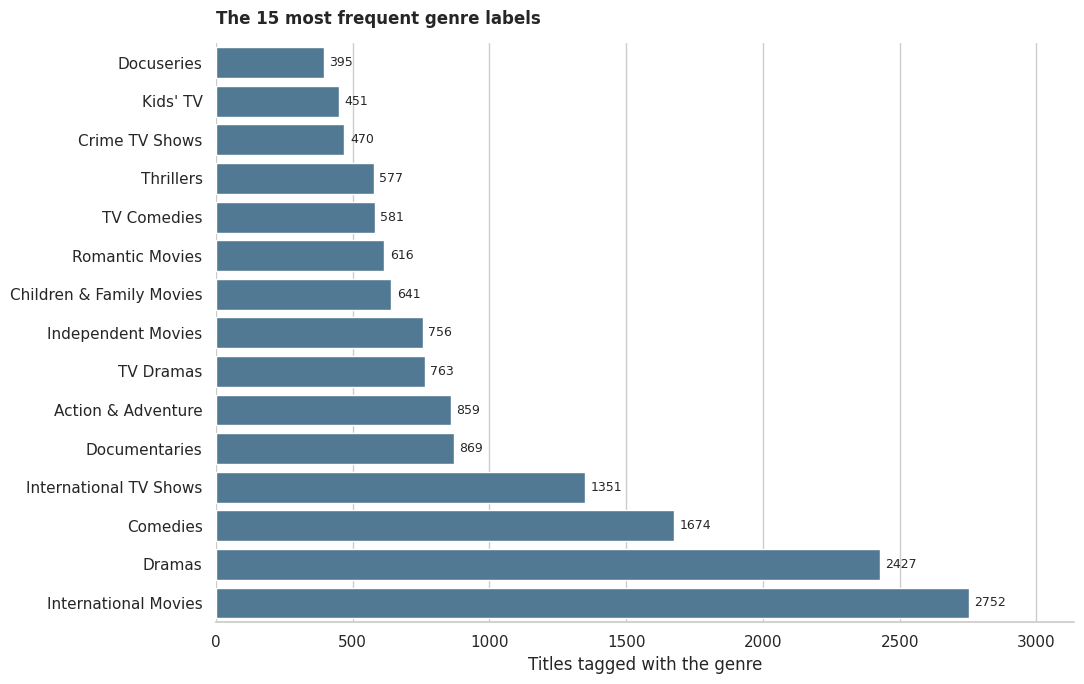

In [17]:
fig, ax = plt.subplots(figsize=(11, 7))
plot_data = top_15_genres.sort_values("title_count", ascending=True)
sns.barplot(
    data=plot_data,
    x="title_count",
    y="genre",
    color="#477B9E",
    ax=ax
)
ax.set_title("The 15 most frequent genre labels", loc="left", weight="bold", pad=14)
ax.set_xlabel("Titles tagged with the genre")
ax.set_ylabel("")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=9)
ax.set_xlim(0, plot_data["title_count"].max() * 1.14)
sns.despine(ax=ax, left=True, bottom=False)
plt.tight_layout()
plt.show()

## Visualization: country portfolio

The grouped bars separate Movie and TV Show credits within the ten most represented countries. The contrast highlights markets with a more film-led or series-led catalog profile.

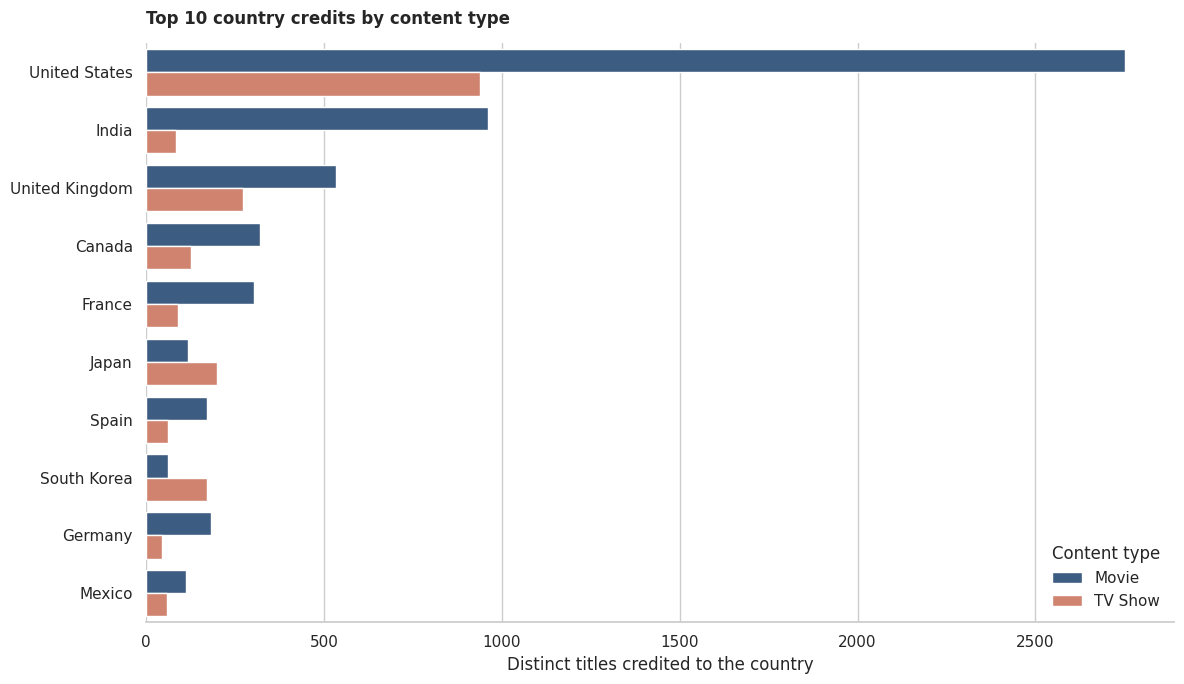

In [18]:
country_plot = (
    country_type[["Movie", "TV Show"]]
    .reset_index()
    .melt(id_vars="country_item", var_name="type", value_name="titles")
)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=country_plot,
    x="titles",
    y="country_item",
    hue="type",
    order=top_10_countries,
    palette=TYPE_PALETTE,
    ax=ax
)
ax.set_title("Top 10 country credits by content type", loc="left", weight="bold", pad=14)
ax.set_xlabel("Distinct titles credited to the country")
ax.set_ylabel("")
ax.legend(title="Content type", frameon=False, loc="lower right")
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

## Visualization: series length

The one-season segment is substantially larger than every other season band. The percentage labels make the short-series profile visible alongside absolute title counts.

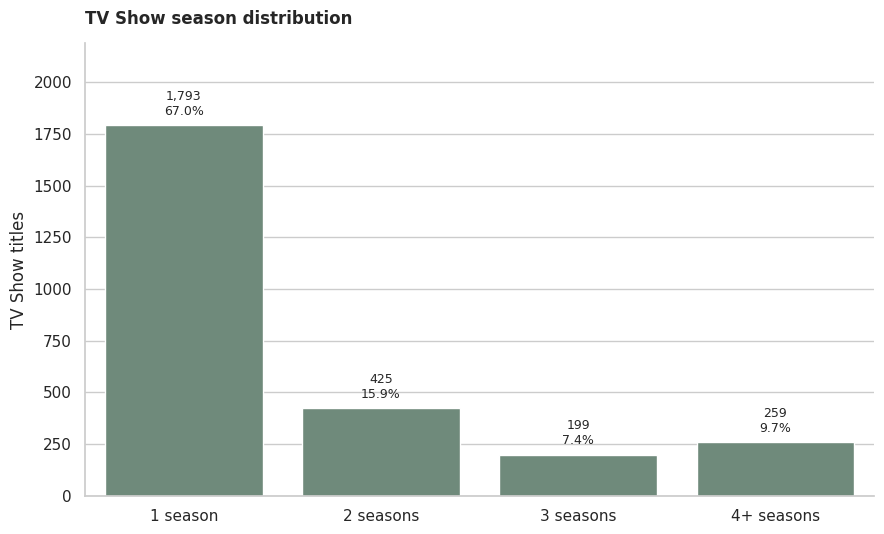

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.5))
season_plot = season_distribution.reset_index().rename(columns={"season_bucket": "season_band"})
sns.barplot(
    data=season_plot,
    x="season_band",
    y="titles",
    color="#6A8F7B",
    ax=ax
)
ax.set_title("TV Show season distribution", loc="left", weight="bold", pad=14)
ax.set_xlabel("")
ax.set_ylabel("TV Show titles")
for index, row in season_plot.iterrows():
    ax.text(
        index,
        row["titles"] + 35,
        f"{int(row['titles']):,}\n{row['share_pct']:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )
ax.set_ylim(0, season_plot["titles"].max() * 1.22)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## Visualization: addition seasonality

Monthly additions are aggregated over the full date range. July is the highest month in this extract, with December and September also showing relatively high volumes.

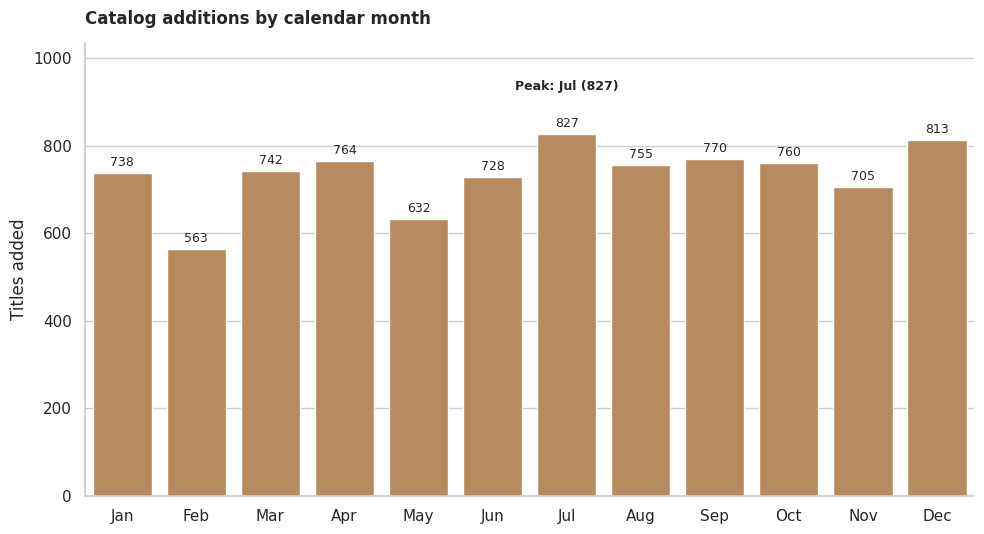

In [20]:
fig, ax = plt.subplots(figsize=(10, 5.5))
month_plot = monthly_summary.reset_index().rename(columns={"index": "month"})
bars = sns.barplot(
    data=month_plot,
    x="month",
    y="titles",
    color="#C58B52",
    ax=ax
)
ax.set_title("Catalog additions by calendar month", loc="left", weight="bold", pad=14)
ax.set_xlabel("")
ax.set_ylabel("Titles added")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)
peak_month = monthly_summary["titles"].idxmax()
peak_value = monthly_summary["titles"].max()
ax.text(
    month_names.index(peak_month) if peak_month in month_names else 6,
    peak_value * 1.12,
    f"Peak: {peak_month} ({peak_value:,})",
    ha="center",
    fontsize=9,
    weight="bold"
)
ax.set_ylim(0, peak_value * 1.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## Visualization: rating architecture

The heatmap expresses each rating as a percentage of its own content type. This within-format normalization makes the Movie and TV Show profiles comparable despite their different catalog sizes.

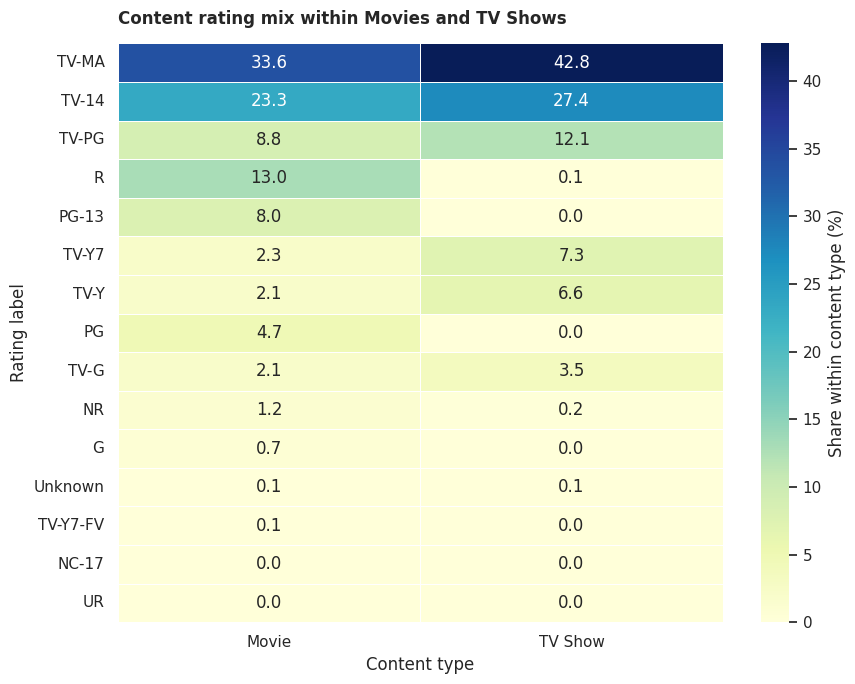

In [21]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    rating_share_by_type,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Share within content type (%)"},
    ax=ax
)
ax.set_title("Content rating mix within Movies and TV Shows", loc="left", weight="bold", pad=14)
ax.set_xlabel("Content type")
ax.set_ylabel("Rating label")
plt.tight_layout()
plt.show()

## Visualization: director genre signatures

The matrix shows how the five most prolific credited directors are distributed across their catalog genre labels. Sparse rows are expected because several directors specialize in a narrow format.

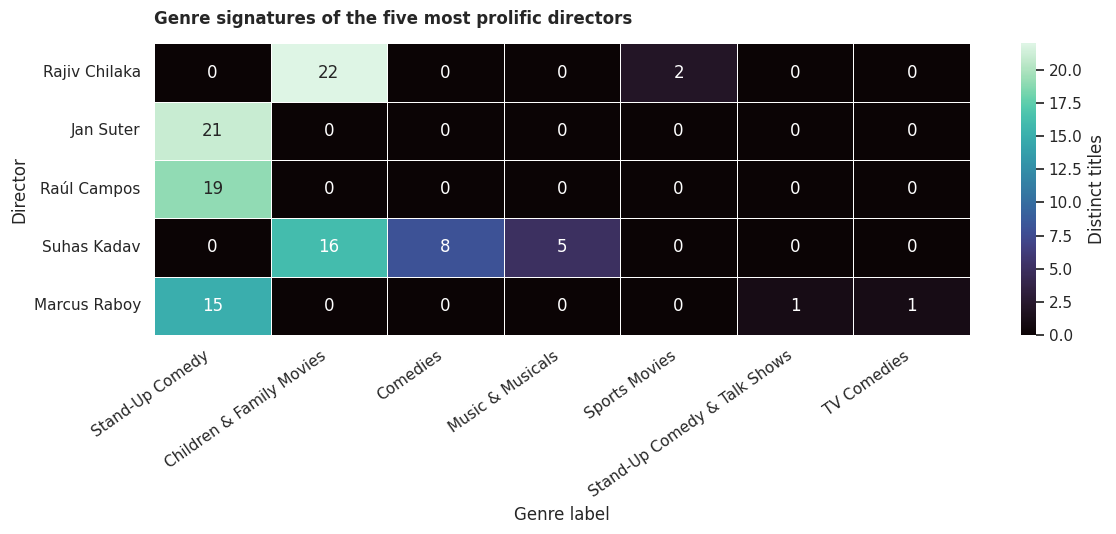

In [22]:
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(
    director_genre_matrix,
    annot=True,
    fmt="g",
    cmap="mako",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Distinct titles"},
    ax=ax
)
ax.set_title("Genre signatures of the five most prolific directors", loc="left", weight="bold", pad=14)
ax.set_xlabel("Genre label")
ax.set_ylabel("Director")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Strategic readout

The data points to a catalog with a persistent film majority, a growing but not dominant TV Show contribution, strong international genre representation and a concentrated group of leading genre labels. Country and director credits add useful portfolio detail, while the addition-date and release-year fields reveal different aspects of catalog timing.

In [23]:
movie_share_pre_2015 = (
    analysis_df.loc[analysis_df["year_added"].lt(2015), "type"].eq("Movie").mean() * 100
)
tv_share_2019 = yearly_share.loc[2019, "TV Show"]
peak_year = int(yearly_counts.sum(axis=1).idxmax())
peak_year_titles = int(yearly_counts.sum(axis=1).max())
peak_month_name = monthly_summary["titles"].idxmax()
peak_month_titles = int(monthly_summary["titles"].max())
top_genre_name = genre_counts.index[0]
top_genre_titles = int(genre_counts.iloc[0])
top_country_name = country_counts.index[0]
top_country_titles = int(country_counts.iloc[0])
top_director_name = director_counts.index[0]
top_director_titles = int(director_counts.iloc[0])

insight_table = pd.DataFrame({
    "theme": [
        "Catalog balance",
        "Addition-year peak",
        "Genre leadership",
        "Country concentration",
        "Series length",
        "Seasonality",
        "Director concentration"
    ],
    "observed_result": [
        f"Movies account for {df['type'].eq('Movie').mean() * 100:.1f}% of all titles.",
        f"{peak_year} is the peak year with {peak_year_titles:,} additions.",
        f"{top_genre_name} leads with {top_genre_titles:,} title credits.",
        f"{top_country_name} leads with {top_country_titles:,} country credits.",
        f"{season_distribution.loc['1 season', 'share_pct']:.1f}% of TV Shows have one season.",
        f"{peak_month_name} leads with {peak_month_titles:,} additions.",
        f"{top_director_name} leads with {top_director_titles} credited titles."
    ]
})
display(insight_table)

,theme,observed_result
0,Catalog balance,Movies account for 69.6% of all titles.
1,Addition-year peak,"2019 is the peak year with 2,016 additions."
2,Genre leadership,"International Movies leads with 2,752 title cr..."
3,Country concentration,"United States leads with 3,690 country credits."
4,Series length,67.0% of TV Shows have one season.
5,Seasonality,Jul leads with 827 additions.
6,Director concentration,Rajiv Chilaka leads with 22 credited titles.


## Interpretation boundaries

Country and genre counts are multi-label associations, not mutually exclusive title totals. Addition-year counts reflect the date recorded in this dataset and do not prove the timing or commercial rationale of licensing decisions. The 2021 observation window ends in September, and the rating labels combine film and television classification systems.